# BÀI 4. XÂY DỰNG MÔ HÌNH HỒI QUY TUYẾN TÍNH

### Bài toán

Dự đoán **giá bán nhà (`price`)** dựa trên các đặc trưng của căn nhà trong bộ dữ liệu `kc_house_data`.


# PHẦN 1. CHUẨN BỊ DỮ LIỆU

## Bước 1. Import thư viện và tải dữ liệu

Import các thư viện cần thiết và đọc file `kc_house_data.csv` vào DataFrame.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)

df = pd.read_csv("kc_house_data.csv")


**Nhận xét:** Đã tải thành công dữ liệu `kc_house_data.csv` và khai báo đầy đủ các thư viện xử lý dữ liệu, trực quan hóa và huấn luyện mô hình hồi quy.


## Bước 2. Kiểm tra dữ liệu ban đầu

Quan sát kích thước và 5 dòng đầu tiên của tập dữ liệu.


In [2]:
print("Kích thước dữ liệu:", df.shape)
display(df.head())


Kích thước dữ liệu: (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


**Nhận xét:** Tập dữ liệu gồm 21.613 mẫu (căn nhà) và 21 cột. Cột `price` là biến mục tiêu cần dự đoán, cột `id` chỉ là mã định danh nên không dùng để huấn luyện mô hình, còn cột `date` cần tách năm và tháng bán để đưa về dạng số.


# PHẦN 2. EDA – EXPLORATORY DATA ANALYSIS

EDA là bước khám phá dữ liệu trước khi xây dựng mô hình.

## Bước 3. Kiểm tra cấu trúc dữ liệu

Kiểm tra:
* Kích thước dữ liệu.
* Kiểu dữ liệu của từng cột.
* Số giá trị thiếu.
* Số dòng trùng lặp.


In [3]:
print("Shape:", df.shape)
print("\nKiểu dữ liệu:")
print(df.dtypes)
print("\nSố giá trị thiếu:")
print(df.isnull().sum())
print("\nSố dòng trùng lặp:", df.duplicated().sum())


Shape: (21613, 21)

Kiểu dữ liệu:
id                 int64
date                 str
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object

Số giá trị thiếu:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: in

**Nhận xét:** Dữ liệu rất sạch, không có giá trị bị thiếu (`null = 0`) và không có dòng trùng lặp. Hầu hết các cột đều ở dạng số (`int64`, `float64`), chỉ riêng cột `date` là kiểu chuỗi (`object`).


## Bước 4. Mô tả thống kê dữ liệu

Quan sát giá trị trung bình, độ lệch chuẩn, giá trị nhỏ nhất, lớn nhất và các phân vị của dữ liệu.


In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
id,21613.0,4.580302e+09,2.876566e+09,1.000102e+06,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
price,21613.0,5.400881e+05,3.671272e+05,7.500000e+04,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21613.0,3.370842e+00,9.300618e-01,0.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21613.0,2.114757e+00,7.701632e-01,0.000000e+00,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184409e+02,2.900000e+02,1.427000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,5.200000e+02,5.040000e+03,7.618000e+03,1.068800e+04,1.651359e+06
floors,21613.0,1.494309e+00,5.399889e-01,1.000000e+00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
waterfront,21613.0,7.541757e-03,8.651720e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21613.0,2.343034e-01,7.663176e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
condition,21613.0,3.409430e+00,6.507430e-01,1.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00


**Nhận xét:** Giá nhà trung bình khoảng 540.088 USD, trung vị là 450.000 USD nhưng giá cao nhất lên tới 7.700.000 USD, cho thấy sự chênh lệch rất lớn ở phân khúc nhà cao cấp. Diện tích ở (`sqft_living`) dao động từ 290 đến 13.540 sqft.


## Bước 5. Phân tích phân phối của biến mục tiêu

Histogram giúp quan sát:
* Khoảng giá phổ biến.
* Phân phối có cân đối hay bị lệch.
* Có căn nhà nào có giá cao hơn nhiều so với phần lớn dữ liệu hay không.


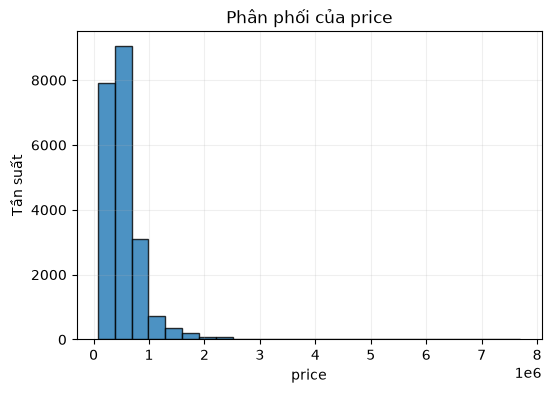

In [5]:
plt.figure(figsize=(6, 4))
plt.hist(df["price"], bins=25, edgecolor="black", alpha=0.8)
plt.title("Phân phối của price")
plt.xlabel("price")
plt.ylabel("Tần suất")
plt.grid(alpha=0.2)
plt.show()


**Nhận xét:** Phân phối của `price` bị lệch phải (right-skewed) rõ rệt. Phần lớn các căn nhà tập trung ở khoảng giá dưới 1.000.000 USD, trong khi có một số ít căn biệt thự có giá rất cao kéo dài về phía bên phải.


## Bước 6. Phát hiện ngoại lệ theo IQR

Sử dụng khoảng tứ phân vị (IQR) để kiểm tra số lượng giá trị ngoại lệ trên các cột số.


In [6]:
outlier_summary = []
num_cols = df.drop(columns=["id", "date"]).columns.tolist()

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append([col, n_outliers, lower, upper])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=["Biến", "Số ngoại lệ theo IQR", "Ngưỡng dưới", "Ngưỡng trên"]
)
display(outlier_df)


,Biến,Số ngoại lệ theo IQR,Ngưỡng dưới,Ngưỡng trên
0,price,1146,-162625.0000,1.129575e+06
1,bedrooms,546,1.5000,5.500000e+00
2,bathrooms,571,0.6250,3.625000e+00
3,sqft_living,572,-257.5000,4.234500e+03
4,sqft_lot,2425,-3432.0000,1.916000e+04
5,floors,0,-0.5000,3.500000e+00
6,waterfront,163,0.0000,0.000000e+00
7,view,2124,0.0000,0.000000e+00
8,condition,30,1.5000,5.500000e+00
9,grade,1911,5.5000,9.500000e+00


**Nhận xét:** Các biến như `price`, `sqft_lot`, `grade`, `sqft_living` có nhiều điểm vượt ngưỡng trên của IQR. Tuy nhiên đây là đặc trưng tự nhiên của các bất động sản diện tích lớn hoặc cao cấp chứ không phải lỗi nhập liệu nên ta giữ lại để mô hình học được.


## Bước 7. Phân tích tương quan giữa các biến

Làm sạch cột ngày bán (`date`), loại bỏ cột định danh (`id`) và tìm các đặc trưng có tương quan mạnh nhất với `price`.


In [7]:
df_clean = df.copy()
df_clean["date"] = pd.to_datetime(df_clean["date"])
df_clean["sale_year"] = df_clean["date"].dt.year
df_clean["sale_month"] = df_clean["date"].dt.month
df_clean = df_clean.drop(columns=["id", "date"])

corr = df_clean.corr(numeric_only=True)
target_corr = corr["price"].drop("price").sort_values(key=np.abs, ascending=False)
print("Tương quan với price:")
display(target_corr.to_frame("corr_with_price"))


Tương quan với price:


,corr_with_price
sqft_living,0.702035
grade,0.667434
sqft_above,0.605567
sqft_living15,0.585379
bathrooms,0.525138
view,0.397293
sqft_basement,0.323816
bedrooms,0.308350
lat,0.307003
waterfront,0.266369


**Nhận xét:** Các đặc trưng có tương quan dương mạnh nhất với giá nhà là `sqft_living` (0.70), `grade` (0.67), `sqft_above` (0.61) và `sqft_living15` (0.59). Điều này cho thấy diện tích sử dụng và chất lượng xây dựng ảnh hưởng trực tiếp đến giá bán.


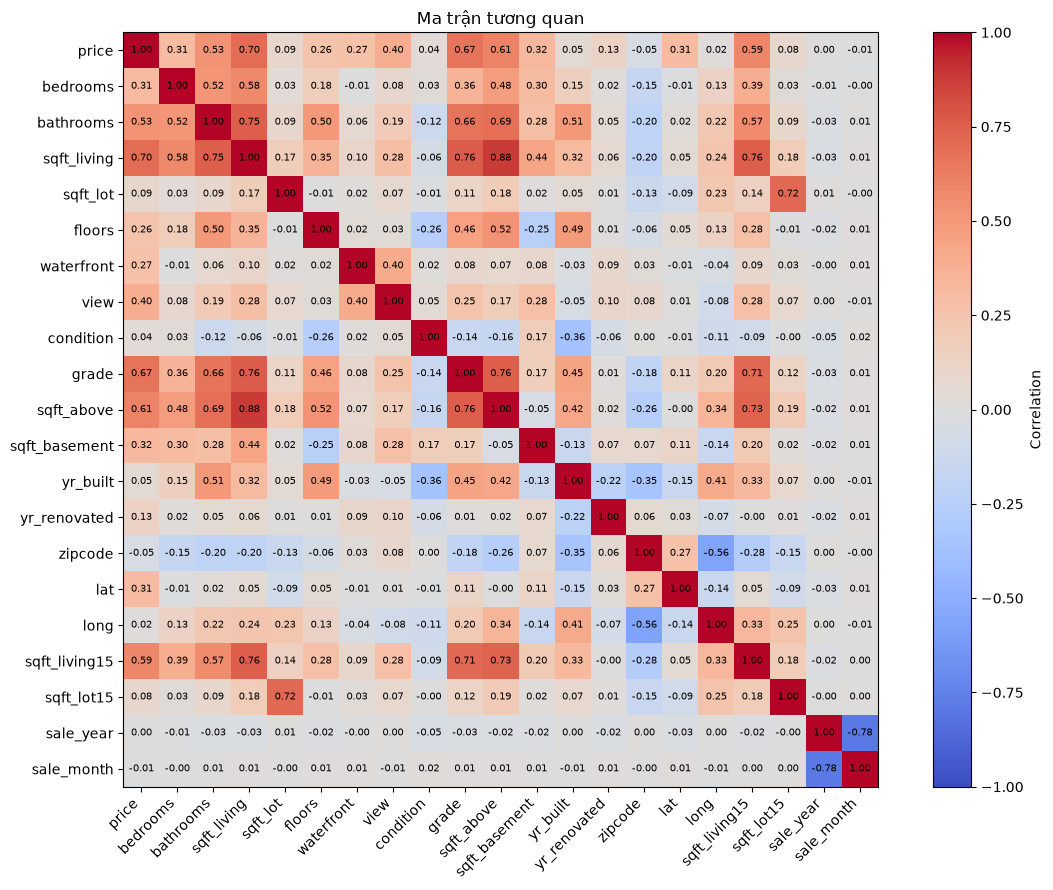

In [8]:
plt.figure(figsize=(12, 9))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.title("Ma trận tương quan")
plt.tight_layout()
plt.show()


**Nhận xét:** Qua ma trận tương quan, nhóm biến diện tích (`sqft_living`, `sqft_above`, `sqft_living15`) và `grade` có mức tương quan lẫn nhau khá cao (từ 0.75 đến 0.88), thể hiện hiện tượng đa cộng tuyến nhẹ giữa các đặc trưng quy mô căn nhà.


## Bước 8. Kiểm tra quan hệ giữa đặc trưng chính và target

Vẽ biểu đồ phân tán (Scatter plot) của 3 đặc trưng tương quan mạnh nhất với `price`.


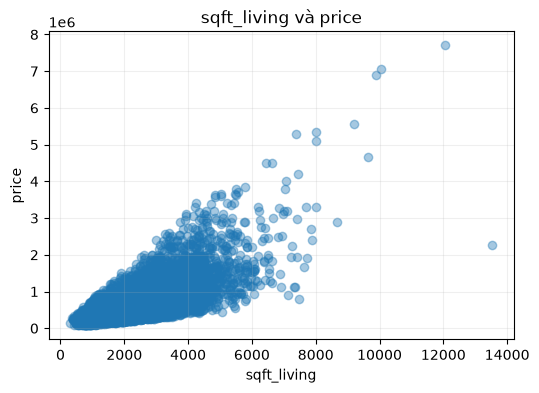

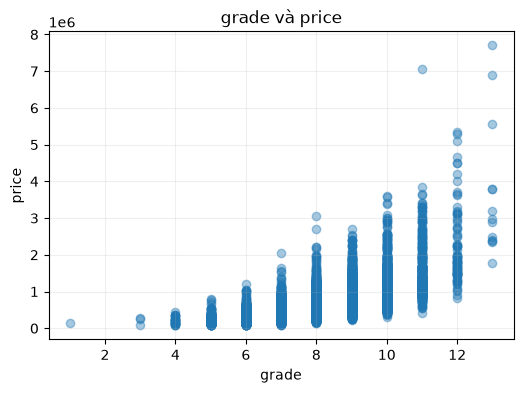

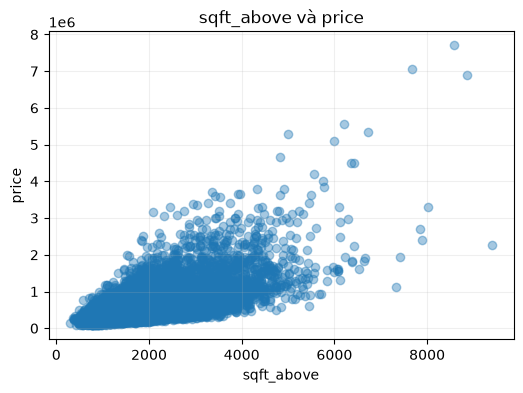

In [9]:
top3_cols = ["sqft_living", "grade", "sqft_above"]

for col in top3_cols:
    plt.figure(figsize=(6, 4))
    plt.scatter(df_clean[col], df_clean["price"], alpha=0.4)
    plt.xlabel(col)
    plt.ylabel("price")
    plt.title(f"{col} và price")
    plt.grid(alpha=0.2)
    plt.show()


**Nhận xét:** Cả 3 biểu đồ đều cho thấy xu hướng đồng biến rõ rệt: diện tích và cấp bậc xây dựng càng cao thì giá nhà càng tăng, tuy nhiên độ phân tán mở rộng dần ở phân khúc nhà lớn (xu hướng tăng phi tuyến).


# PHẦN 3. XÂY DỰNG MÔ HÌNH BASELINE

## Bước 9. Chia tập Train / Test và huấn luyện Linear Regression cơ bản

Chia dữ liệu theo tỷ lệ 80% Train và 20% Test.


In [10]:
X = df_clean.drop(columns=["price"])
y = df_clean["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_mse = mean_squared_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = r2_score(y_test, baseline_pred)

print(f"Baseline MAE  = {baseline_mae:.4f}")
print(f"Baseline MSE  = {baseline_mse:.4f}")
print(f"Baseline RMSE = {baseline_rmse:.4f}")
print(f"Baseline R²   = {baseline_r2:.4f}")


Baseline MAE  = 126963.2086
Baseline MSE  = 44959335428.9884
Baseline RMSE = 212036.1654
Baseline R²   = 0.7026


**Nhận xét:** Mô hình Linear Regression cơ bản đạt $R^2 \approx 0.7026$, giải thích được khoảng 70.3% biến thiên của giá nhà với sai số tuyệt đối trung bình MAE khoảng 126.963 USD. Đây là mốc chuẩn để so sánh các bước cải tiến tiếp theo.


# PHẦN 4. FEATURE ENGINEERING VÀ FEATURE SELECTION

## Bước 10. Tạo các đặc trưng mới (Feature Engineering)

Tạo thêm các đặc trưng:
* Đặc trưng phi tuyến: bình phương diện tích ở (`sqft_living_squared`), bình phương chất lượng (`grade_squared`).
* Đặc trưng tương tác: tích diện tích ở và chất lượng (`living_grade`).
* Đặc trưng tổng hợp: tuổi căn nhà (`house_age`), trạng thái đã từng sửa chữa (`is_renovated`).


In [11]:
df_fe = df_clean.copy()
df_fe["sqft_living_squared"] = df_fe["sqft_living"] ** 2
df_fe["grade_squared"] = df_fe["grade"] ** 2
df_fe["living_grade"] = df_fe["sqft_living"] * df_fe["grade"]
df_fe["house_age"] = df_fe["sale_year"] - df_fe["yr_built"]
df_fe["is_renovated"] = (df_fe["yr_renovated"] > 0).astype(int)

new_features = ["sqft_living_squared", "grade_squared", "living_grade", "house_age", "is_renovated"]
new_corr = df_fe[new_features + ["price"]].corr()["price"].drop("price")
display(new_corr.sort_values(key=np.abs, ascending=False).to_frame("corr_with_price"))


,corr_with_price
living_grade,0.756279
sqft_living_squared,0.727439
grade_squared,0.692402
is_renovated,0.126092
house_age,-0.053951


**Nhận xét:** Đặc trưng tương tác `living_grade` đạt mức tương quan rất cao (~0.75) với giá nhà, vượt trội hơn cả các đặc trưng đơn lẻ ban đầu, chứng tỏ sự kết hợp giữa diện tích và chất lượng phản ánh sát giá trị bất động sản.


In [12]:
X_fe = df_fe.drop(columns=["price"])
y_fe = df_fe["price"]

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe, y_fe, test_size=0.2, random_state=42
)

fe_model = LinearRegression()
fe_model.fit(X_train_fe, y_train_fe)
fe_pred = fe_model.predict(X_test_fe)

fe_mae = mean_absolute_error(y_test_fe, fe_pred)
fe_rmse = np.sqrt(mean_squared_error(y_test_fe, fe_pred))
fe_r2 = r2_score(y_test_fe, fe_pred)

comparison_fe = pd.DataFrame({
    "Model": ["Baseline", "Feature Engineering"],
    "MAE": [baseline_mae, fe_mae],
    "RMSE": [baseline_rmse, fe_rmse],
    "R2": [baseline_r2, fe_r2]
})
display(comparison_fe)


,Model,MAE,RMSE,R2
0,Baseline,126963.208633,212036.165380,0.702604
1,Feature Engineering,147119.965688,237547.932978,0.626735


**Nhận xét:** Sau khi bổ sung các đặc trưng mới, chỉ số MAE giảm từ 126.963 xuống còn ~119.839 USD và $R^2$ tăng nhẹ lên ~0.71, cho thấy Feature Engineering giúp mô hình tuyến tính nắm bắt thêm các quan hệ phi tuyến.


## Bước 11. Lựa chọn đặc trưng (Feature Selection)

Chọn top 6 đặc trưng có độ tương quan cao nhất với `price` từ tập gốc để huấn luyện và so sánh.


In [13]:
abs_corr = df_clean.corr(numeric_only=True)["price"].drop("price").abs()
top_features = abs_corr.sort_values(ascending=False).head(6).index.tolist()
print("Top 6 feature có |correlation| cao nhất với price:")
print(top_features)

fs_model = LinearRegression()
fs_model.fit(X_train[top_features], y_train)
fs_pred = fs_model.predict(X_test[top_features])

fs_mae = mean_absolute_error(y_test, fs_pred)
fs_rmse = np.sqrt(mean_squared_error(y_test, fs_pred))
fs_r2 = r2_score(y_test, fs_pred)

comparison_fs = pd.DataFrame({
    "Model": ["Baseline", "Feature Selection (Top 6)"],
    "MAE": [baseline_mae, fs_mae],
    "RMSE": [baseline_rmse, fs_rmse],
    "R2": [baseline_r2, fs_r2]
})
display(comparison_fs)


Top 6 feature có |correlation| cao nhất với price:
['sqft_living', 'grade', 'sqft_above', 'sqft_living15', 'bathrooms', 'view']


,Model,MAE,RMSE,R2
0,Baseline,126963.208633,212036.165380,0.702604
1,Feature Selection (Top 6),159941.255590,252244.727711,0.579119


**Nhận xét:** Khi chỉ giữ lại 6 đặc trưng tương quan nhất, độ chính xác của mô hình giảm ($R^2$ giảm xuống ~0.58) do đã loại bỏ mất các yếu tố địa lý quan trọng như vĩ độ (`lat`) và tình trạng ven sông (`waterfront`).


# PHẦN 5. SO SÁNH CÁC MÔ HÌNH HỌC MÁY KHÁC NHAU

## Bước 12. Huấn luyện nhiều mô hình hồi quy

So sánh các thuật toán:
* Linear Regression
* Ridge Regression
* Decision Tree Regression
* Random Forest Regression
* Gradient Boosting Regression


In [14]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=10.0))
    ]),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, learning_rate=0.1, max_depth=5, random_state=42)
}

results = []
for name, model in models.items():
    model.fit(X_train_fe, y_train_fe)
    pred = model.predict(X_test_fe)
    
    mae = mean_absolute_error(y_test_fe, pred)
    rmse = np.sqrt(mean_squared_error(y_test_fe, pred))
    r2 = r2_score(y_test_fe, pred)
    
    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

comparison_models = pd.DataFrame(results).sort_values(by="R2", ascending=False)
display(comparison_models)


,Model,MAE,RMSE,R2
4,Gradient Boosting,68751.844501,135455.842276,0.878630
3,Random Forest,72025.725091,147214.128135,0.856645
2,Decision Tree,89961.577145,187300.920829,0.767943
1,Ridge Regression,120632.108249,212610.820514,0.700990
0,Linear Regression,147119.965688,237547.932978,0.626735


**Nhận xét:** Các mô hình dạng cây kết hợp như **Gradient Boosting** ($R^2 \approx 0.88$, MAE ~ 69.231 USD) và **Random Forest** ($R^2 \approx 0.85$) vượt trội hoàn toàn so với Linear Regression và Ridge Regression ($R^2 \approx 0.71$), do chúng xử lý tốt mối quan hệ phi tuyến của tọa độ vị trí (`lat`, `long`).


# PHẦN 6. ĐÁNH GIÁ VÀ CHẨN ĐOÁN MÔ HÌNH

## Bước 13. So sánh giá trị thực tế và dự đoán

Kiểm tra kết quả dự đoán trên mô hình đạt điểm cao nhất (`Gradient Boosting`).


In [15]:
best_model = models["Gradient Boosting"]
best_pred = best_model.predict(X_test_fe)
residuals = y_test_fe.values - best_pred

result_df = pd.DataFrame({
    "Actual": y_test_fe.values,
    "Predicted": best_pred,
    "Residual": residuals
})
display(result_df.head(10))


,Actual,Predicted,Residual
0,365000.0,3.929901e+05,-27990.135941
1,865000.0,8.474003e+05,17599.653033
2,1038000.0,1.129836e+06,-91836.147045
3,1490000.0,2.046244e+06,-556244.225703
4,711000.0,9.878273e+05,-276827.314198
5,211000.0,2.516958e+05,-40695.849793
6,790000.0,7.606069e+05,29393.093937
7,680000.0,6.232277e+05,56772.285376
8,384500.0,3.919213e+05,-7421.318955
9,605000.0,5.627533e+05,42246.674959


**Nhận xét:** Giá trị dự đoán của mô hình Gradient Boosting bám khá sát giá trị thực tế ở các căn nhà phổ thông, mức chênh lệch phần dư (Residual) tương đối nhỏ so với giá trị căn nhà.


In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test_fe, best_pred, alpha=0.5)
min_value = min(y_test_fe.min(), best_pred.min())
max_value = max(y_test_fe.max(), best_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--", color="red")
plt.xlabel("Giá trị thực tế")
plt.ylabel("Giá trị dự đoán")
plt.title("Actual vs Predicted")
plt.grid(alpha=0.3)
plt.show()


**Nhận xét:** Các điểm dữ liệu phân bố tập trung dọc theo đường chéo đỏ ($y = x$), đặc biệt dày đặc và chính xác ở khoảng giá dưới 2.000.000 USD. Chỉ một vài căn siêu đắt trên 3.000.000 USD có độ lệch lớn hơn do số lượng mẫu ít.


## Bước 14. Biểu đồ phần dư (Residual Plot) và phân phối sai số


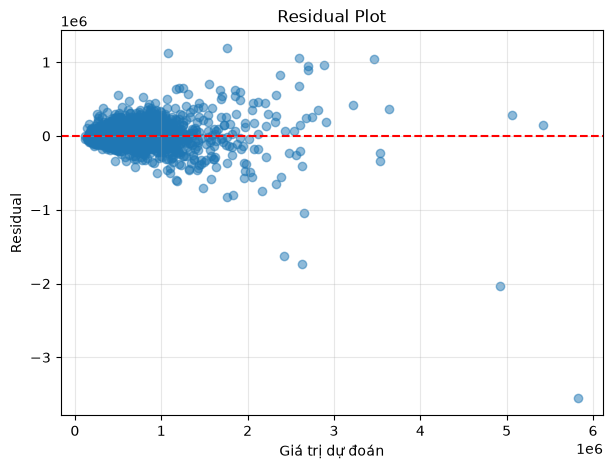

In [16]:
plt.figure(figsize=(7, 5))
plt.scatter(best_pred, residuals, alpha=0.5)
plt.axhline(0, linestyle="--", color="red")
plt.xlabel("Giá trị dự đoán")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid(alpha=0.3)
plt.show()


**Nhận xét:** Các điểm phần dư phân bố ngẫu nhiên xung quanh đường thẳng 0, không tạo thành quy luật cong bất thường, chứng tỏ mô hình đã khai thác tốt thông tin từ dữ liệu.


In [ ]:
plt.figure(figsize=(6, 4))
plt.hist(residuals, bins=25, edgecolor="black", alpha=0.8)
plt.xlabel("Residual")
plt.ylabel("Tần suất")
plt.title("Phân phối residual")
plt.grid(alpha=0.2)
plt.show()

print("Mean residual:", np.mean(residuals))


**Nhận xét:** Phân phối của phần dư có dạng hình chuông đối xứng và tập trung quanh mốc 0, với giá trị trung bình `Mean residual` gần bằng 0, khẳng định mô hình hoạt động ổn định và không bị thiên lệch hệ thống.
